In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import joblib, os

train = pd.read_csv("../data/fraudTrain.csv")
test  = pd.read_csv("../data/fraudTest.csv")
df = pd.concat([train, test], ignore_index=True).drop(columns=["Unnamed: 0"])
del train, test

In [2]:
print(df.isnull().sum())

trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64


In [3]:
print("Doublons :", df.duplicated().sum())

Doublons : 0


In [4]:
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df["dob"] = pd.to_datetime(df["dob"])

df["age"] = (df["trans_date_trans_time"] - df["dob"]).dt.days // 365
df["hour"] = df["trans_date_trans_time"].dt.hour
df["day_of_week"] = df["trans_date_trans_time"].dt.dayofweek

# Distance client ↔ commerçant (km), à partir des coordonnées GPS
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df["lat"], df["long"], df["merch_lat"], df["merch_long"])

In [5]:
# Âge → tranches (bornes et labels du cours)
bins = [0, 18, 40, 65, 120]
labels = ['Jeune', 'Adulte', 'Sénior', 'Âgé']
df['tranche_age'] = pd.cut(df['age'], bins=bins, labels=labels)

# Heure → période de la journée
df['periode'] = pd.cut(df['hour'], bins=[-1, 5, 11, 17, 23],
                       labels=['Nuit', 'Matin', 'Après-midi', 'Soir'])

print(df.groupby('tranche_age', observed=True)['is_fraud'].mean() * 100)
print(df.groupby('periode', observed=True)['is_fraud'].mean() * 100)

tranche_age
Jeune     0.534012
Adulte    0.455923
Sénior    0.532826
Âgé       0.671967
Name: is_fraud, dtype: float64
periode
Nuit          0.931070
Matin         0.098639
Après-midi    0.101405
Soir          0.943817
Name: is_fraud, dtype: float64


In [6]:
Q1 = df['amt'].quantile(0.25)
Q3 = df['amt'].quantile(0.75)
IQR = Q3 - Q1
LB = Q1 - 1.5 * IQR
UB = Q3 + 1.5 * IQR
outliers = df[(df['amt'] < LB) | (df['amt'] > UB)]

print("Nombre d'outliers :", len(outliers), f"({len(outliers)/len(df)*100:.1f} %)")
print("Taux de fraude chez les outliers :", outliers['is_fraud'].mean() * 100, "%")
print("Taux de fraude global            :", df['is_fraud'].mean() * 100, "%")

Nombre d'outliers : 95054 (5.1 %)
Taux de fraude chez les outliers : 7.698781745113303 %
Taux de fraude global            : 0.5210014716091717 %


In [7]:
z_scores = stats.zscore(df['amt'])
print("Outliers (|Z| > 3) :", (np.abs(z_scores) > 3).sum())


Outliers (|Z| > 3) : 17846


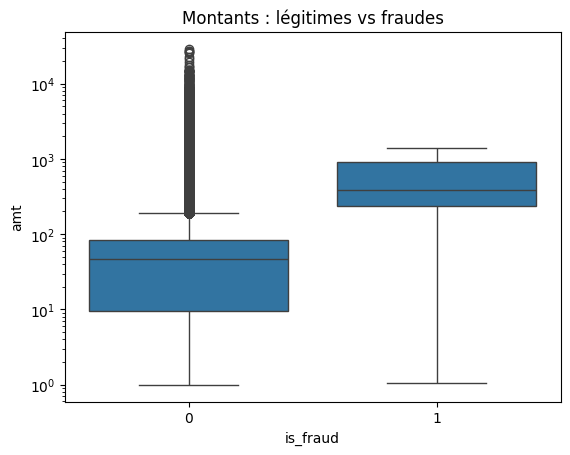

In [8]:
sns.boxplot(x='is_fraud', y='amt', data=df)
plt.yscale('log')
plt.title("Montants : légitimes vs fraudes")
plt.show()